**Assignment 2 – Neural Network Regression with PyTorch**

Group9: Hatice AY, Bedia Nur ELMAS, Mahyar Naeimi

Exercise 1 trains a small neural network on the QSAR Fish Toxicity data with early stopping. Exercise 2 adds a non-negativity constraint to the network for the California Housing data. The datasets are downloaded automatically by scikit-learn, so an internet connection is needed.

In [1]:
# Packages used in this notebook
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import fetch_openml, fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr

# Fixed seeds so that the results can be reproduced
SEED = 42
np.random.seed(SEED)
_ = torch.manual_seed(SEED)

**Exercise 1 – Regression and Early Stopping in PyTorch**

**Step 1 – Load the dataset**

In [2]:
data = fetch_openml(name="qsar_fish_toxicity", version=7, as_frame=True)
X = data.data
y = data.target.astype(float)

print("Shape of X:", X.shape)
print("Features:", list(X.columns))
print("Missing values:", int(X.isna().sum().sum()))
print()
print("Target LC50 [-log(mol/L)]")
print(f"mean = {y.mean():.3f}")
print(f"std  = {y.std():.3f}")
print(f"min  = {y.min():.3f}")
print(f"max  = {y.max():.3f}")

Shape of X: (908, 6)
Features: ['CIC0', 'SM1_Dz', 'GATS1i', 'NdsCH', 'NdssC', 'MLOGP']
Missing values: 0

Target LC50 [-log(mol/L)]
mean = 4.064
std  = 1.456
min  = 0.053
max  = 9.612


In [3]:
X.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
CIC0,908.0,2.898,0.756,0.667,2.347,2.934,3.407,5.926
SM1_Dz,908.0,0.628,0.428,0.000,0.223,0.570,0.893,2.171
GATS1i,908.0,1.294,0.394,0.396,0.951,1.240,1.562,2.920
NdsCH,908.0,0.229,0.605,0.000,0.000,0.000,0.000,4.000
NdssC,908.0,0.486,0.861,0.000,0.000,0.000,1.000,6.000
MLOGP,908.0,2.109,1.433,-2.884,1.209,2.127,3.105,6.515


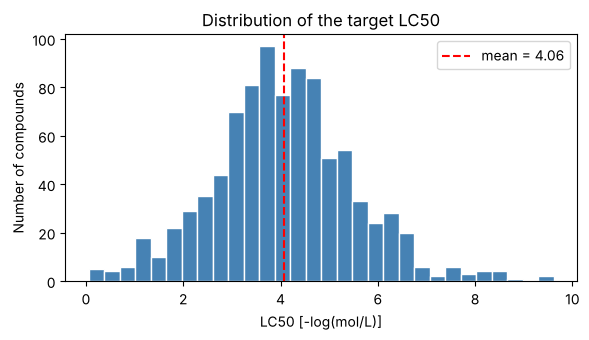

In [4]:
# Distribution of the target
plt.figure(figsize=(6, 3.5))
plt.hist(y, bins=30, color="steelblue", edgecolor="white")
plt.axvline(y.mean(), color="red", linestyle="--", label=f"mean = {y.mean():.2f}")
plt.xlabel("LC50 [-log(mol/L)]")
plt.ylabel("Number of compounds")
plt.title("Distribution of the target LC50")
plt.legend()
plt.tight_layout()
plt.show()

**Findings**

The dataset has 908 compounds and 6 numeric molecular descriptors [1]. There are no missing values.

The target LC50 has a mean of 4.06 and a standard deviation of 1.46, and it ranges from 0.05 to 9.61. The histogram is roughly bell-shaped with a slight tail to the right, so a few compounds are much more toxic than the rest.

The features have different scales. MLOGP (hydrophobicity) goes from -2.9 to 6.5, while SM1_Dz is between 0 and 2.2. NdsCH and NdssC are counts of atom types and are 0 for most compounds. Because of the different scales the features must be standardized before training a neural network.

With only 908 samples the dataset is small, so a small network and a method against overfitting like early stopping make sense.

**Step 2 – Split and preprocess the data**

We first take 20 % of the data as test set. From the remaining 80 % we take 12.5 % as validation set (0.125 × 0.8 = 0.10), so the final split is 70 % / 10 % / 20 %. The scaler is fitted only on the training data, so no information from the validation or test set leaks into training. The target is not scaled, so all losses and metrics are in the original unit of LC50.

In [5]:
# 80 % train+val / 20 % test, then 70 % / 10 % of the whole data
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X.values, y.values, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.125, random_state=SEED)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit only on the training data
X_val_s = scaler.transform(X_val)
X_test_s = scaler.transform(X_test)

print("train:", X_train_s.shape, " val:", X_val_s.shape, " test:", X_test_s.shape)
print("feature means after scaling (train):", X_train_s.mean(axis=0).round(2))
print("feature stds after scaling (train): ", X_train_s.std(axis=0).round(2))

train: (635, 6)  val: (91, 6)  test: (182, 6)
feature means after scaling (train): [-0. -0. -0. -0.  0. -0.]
feature stds after scaling (train):  [1. 1. 1. 1. 1. 1.]


**Step 3 – Create PyTorch datasets and loaders**

The arrays are converted to float32 tensors. The target gets the shape (n, 1) so that it matches the output of the network. Only the training loader is shuffled.

In [6]:
def to_dataset(X_arr, y_arr):
    X_t = torch.tensor(X_arr, dtype=torch.float32)
    y_t = torch.tensor(y_arr, dtype=torch.float32).view(-1, 1)
    return TensorDataset(X_t, y_t)

BATCH_SIZE = 64
train_ds = to_dataset(X_train_s, y_train)
val_ds = to_dataset(X_val_s, y_val)
test_ds = to_dataset(X_test_s, y_test)

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

xb, yb = next(iter(train_loader))
print("one batch:", xb.shape, yb.shape, " batches per epoch:", len(train_loader))

one batch: torch.Size([64, 6]) torch.Size([64, 1])  batches per epoch: 10


**Step 4 – Build a regression network**

Three fully connected layers with 64, 32 and 1 neurons and ReLU between the hidden layers. The last layer has no activation, because the target is a real number. The argument output_activation is not used here, it is needed later in Exercise 2.

In [7]:
class RegressionNet(nn.Module):
    def __init__(self, n_features, output_activation=None):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_features, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1),
        )
        self.output_activation = output_activation   # None = plain linear output

    def forward(self, x):
        out = self.layers(x)
        if self.output_activation is not None:
            out = self.output_activation(out)
        return out

torch.manual_seed(SEED)
model = RegressionNet(n_features=X_train_s.shape[1])
print(model)
print("trainable parameters:", sum(p.numel() for p in model.parameters()))

RegressionNet(
  (layers): Sequential(
    (0): Linear(in_features=6, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
trainable parameters: 2561


**Step 5 – Training loop with early stopping**

Loss function: we use the mean squared error (nn.MSELoss). It is the standard loss for regression, it punishes large errors strongly, and it is the same quantity as the MSE we report in Step 6. The optimizer is torch.optim.SGD with learning rate 0.01 and momentum 0.9.

Early stopping: after every epoch we compute the validation loss. If it is the best so far, we save a copy of model.state_dict(). If the validation loss does not improve for 10 epochs in a row (patience = 10), we stop. At the end we load the saved best weights back into the model. This is the standard early stopping rule described in [3] and [4].

In [8]:
def evaluate_loss(model, loader, loss_fn):
    # average loss over a whole data set, without gradient computation
    model.eval()
    total, n = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            total += loss_fn(model(xb), yb).item() * len(xb)
            n += len(xb)
    return total / n


def train_with_early_stopping(model, train_loader, val_loader, lr=0.01, momentum=0.9,
                              max_epochs=200, patience=10, verbose=True):
    loss_fn = nn.MSELoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=momentum)

    history = {"train": [], "val": []}
    best_val, best_epoch, best_weights = float("inf"), 0, None
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        # training on mini-batches
        model.train()
        running, n = 0.0, 0
        for xb, yb in train_loader:
            optimizer.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
            n += len(xb)
        train_loss = running / n
        val_loss = evaluate_loss(model, val_loader, loss_fn)
        history["train"].append(train_loss)
        history["val"].append(val_loss)

        # early stopping bookkeeping
        if val_loss < best_val:
            best_val, best_epoch = val_loss, epoch
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if verbose and (epoch % 10 == 0 or epoch == 1):
            print(f"epoch {epoch:3d}  train MSE {train_loss:.4f}  val MSE {val_loss:.4f}")
        if epochs_without_improvement >= patience:
            if verbose:
                print(f"Early stopping after epoch {epoch}: no improvement for {patience} epochs.")
            break

    model.load_state_dict(best_weights)   # restore the best model
    if verbose:
        print(f"Best epoch: {best_epoch}, best validation MSE: {best_val:.4f}")
    return history, best_epoch

In [9]:
torch.manual_seed(SEED)
model = RegressionNet(n_features=X_train_s.shape[1])
history, best_epoch = train_with_early_stopping(model, train_loader, val_loader)

epoch   1  train MSE 9.3193  val MSE 1.7280
epoch  10  train MSE 0.7729  val MSE 0.9208


epoch  20  train MSE 0.6693  val MSE 0.8408
epoch  30  train MSE 0.5765  val MSE 0.8149
Early stopping after epoch 33: no improvement for 10 epochs.
Best epoch: 23, best validation MSE: 0.7938


**Step 6 – Evaluation**

In [10]:
def predict(model, X_tensor):
    model.eval()
    with torch.no_grad():
        return model(X_tensor).numpy().ravel()

y_pred = predict(model, test_ds.tensors[0])

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)
r, p_value = pearsonr(y_test, y_pred)   # sklearn.metrics has no Pearson correlation, so we use scipy

# Baseline for comparison: always predict the mean of the training targets
baseline = np.full_like(y_test, y_train.mean())

print("Test set results (neural network)")
print(f"MSE       = {mse:.3f}")
print(f"RMSE      = {np.sqrt(mse):.3f}")
print(f"MAE       = {mae:.3f}")
print(f"R^2       = {r2:.3f}")
print(f"Pearson r = {r:.3f}  (p = {p_value:.1e})")
print()
print(f"Baseline (train mean): MSE = {mean_squared_error(y_test, baseline):.3f}, "
      f"MAE = {mean_absolute_error(y_test, baseline):.3f}, R^2 = {r2_score(y_test, baseline):.3f}")

Test set results (neural network)
MSE       = 0.862
RMSE      = 0.928
MAE       = 0.687
R^2       = 0.644
Pearson r = 0.811  (p = 9.6e-44)

Baseline (train mean): MSE = 2.419, MAE = 1.205, R^2 = -0.000


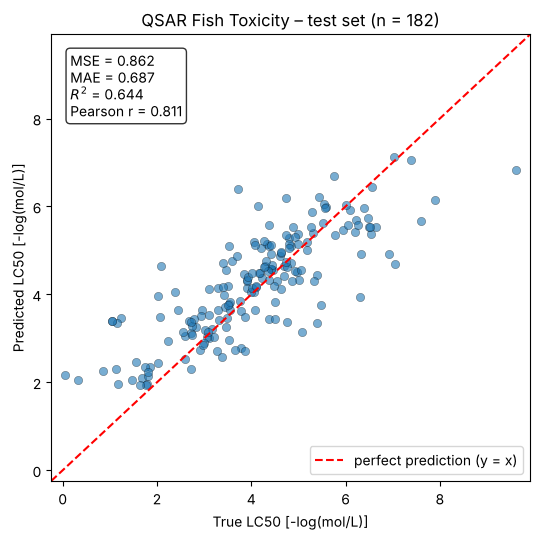

In [11]:
# Predicted vs. true LC50 on the test set
plt.figure(figsize=(5.5, 5.5))
plt.scatter(y_test, y_pred, alpha=0.6, edgecolor="k", linewidth=0.3)
lims = [min(y_test.min(), y_pred.min()) - 0.3, max(y_test.max(), y_pred.max()) + 0.3]
plt.plot(lims, lims, "r--", label="perfect prediction (y = x)")
plt.xlim(lims)
plt.ylim(lims)
plt.xlabel("True LC50 [-log(mol/L)]")
plt.ylabel("Predicted LC50 [-log(mol/L)]")
plt.title(f"QSAR Fish Toxicity – test set (n = {len(y_test)})")
plt.text(0.04, 0.96, f"MSE = {mse:.3f}\nMAE = {mae:.3f}\n$R^2$ = {r2:.3f}\nPearson r = {r:.3f}",
         transform=plt.gca().transAxes, va="top",
         bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

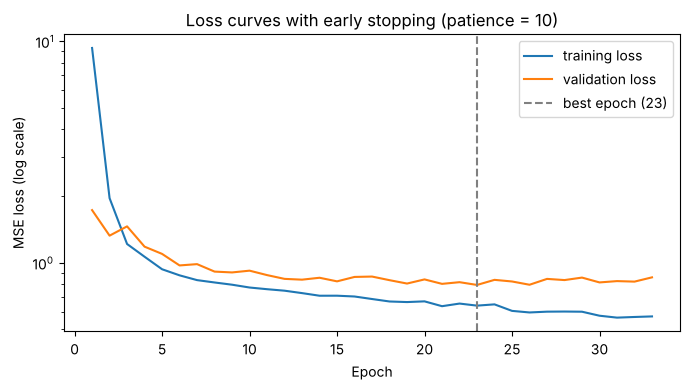

In [12]:
# Training and validation loss curves
epochs = range(1, len(history["train"]) + 1)
plt.figure(figsize=(7, 4))
plt.plot(epochs, history["train"], label="training loss")
plt.plot(epochs, history["val"], label="validation loss")
plt.axvline(best_epoch, color="gray", linestyle="--", label=f"best epoch ({best_epoch})")
plt.xlabel("Epoch")
plt.ylabel("MSE loss (log scale)")
plt.yscale("log")   # the first epoch has a very large loss
plt.title("Loss curves with early stopping (patience = 10)")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation**

Training (the loss plot uses a log scale): the training loss falls quickly in the first epochs and then keeps falling slowly. The validation loss stops improving after epoch 23. After that the training loss still goes down but the validation loss does not, which is the beginning of overfitting. Early stopping ended the training at epoch 33 (10 epochs patience) and restored the weights of epoch 23, so the model did not use all 200 epochs.

Test results: MSE = 0.862, RMSE = 0.93, MAE = 0.69, R² = 0.644 and Pearson r = 0.81. The model explains about 64 % of the variance of LC50 in new compounds. A typical prediction error is about 0.7 log units, which is a factor of about 5 in concentration. The baseline that always predicts the mean has MSE = 2.42 and R² = 0, so the network is clearly much better than guessing.

Scatter plot: the points lie along the y = x line, which agrees with r = 0.81. The model overestimates the toxicity of the least toxic compounds and underestimates the most toxic ones (the cloud is flatter than the diagonal). This is typical for an MSE-trained model on few extreme samples: it pulls predictions towards the mean.

The test MSE (0.86) is a bit higher than the best validation MSE (0.79). The validation set has only 91 compounds, so its loss is noisy, and it was used to choose the stopping epoch. The test set is the fair estimate. Our R² of about 0.64 is in a similar range as the models in the original QSAR study of this dataset [1], which is expected since six simple descriptors cannot describe all toxicity mechanisms.

**Exercise 2 – Encoding Constraints**

We re-use the preprocessing and data loading from the in-class exercise [11] for the California Housing data [2]: a 70 / 10 / 20 split, a StandardScaler fitted on the training data only, TensorDatasets and DataLoaders with batch size 64. The target is the median house value in units of 100,000 $.

In [13]:
housing = fetch_california_housing()
Xh, yh = housing.data, housing.target
print("Shape:", Xh.shape, " features:", housing.feature_names)
print(f"Target: min = {yh.min():.3f}, max = {yh.max():.3f}, mean = {yh.mean():.3f} (x 100k $)")
print("Number of districts with value >= 5.0:", int((yh >= 5.0).sum()))

Xh_trainval, Xh_test, yh_trainval, yh_test = train_test_split(Xh, yh, test_size=0.20, random_state=SEED)
Xh_train, Xh_val, yh_train, yh_val = train_test_split(Xh_trainval, yh_trainval, test_size=0.125, random_state=SEED)

scaler_h = StandardScaler().fit(Xh_train)
h_train_ds = to_dataset(scaler_h.transform(Xh_train), yh_train)
h_val_ds = to_dataset(scaler_h.transform(Xh_val), yh_val)
h_test_ds = to_dataset(scaler_h.transform(Xh_test), yh_test)

h_train_loader = DataLoader(h_train_ds, batch_size=BATCH_SIZE, shuffle=True,
                            generator=torch.Generator().manual_seed(SEED))
h_val_loader = DataLoader(h_val_ds, batch_size=BATCH_SIZE, shuffle=False)
print("train:", len(h_train_ds), " val:", len(h_val_ds), " test:", len(h_test_ds))

Shape: (20640, 8)  features: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
Target: min = 0.150, max = 5.000, mean = 2.069 (x 100k $)
Number of districts with value >= 5.0: 992
train: 14448  val: 2064  test: 4128


**Adaptation of the network**

House prices are never negative, but a plain linear output layer can produce any real number. We therefore put an activation function after the last layer that only gives positive values. The relevant code change is only one argument of the network from Exercise 1:

model = RegressionNet(n_features, output_activation=nn.Softplus())

Softplus(z) = log(1 + exp(z)) is always > 0, smooth, and almost linear for large z, so the gradients stay well behaved [4]. As a second option we also try exp(z), which is also always > 0 but grows very fast. For comparison we train the same network without a constraint. All models use the same training loop with early stopping as in Exercise 1.

In [14]:
class Exp(nn.Module):
    # exp(z) > 0 for every z
    def forward(self, x):
        return torch.exp(x)


def fit_and_test(output_activation, name):
    torch.manual_seed(SEED)
    m = RegressionNet(n_features=Xh.shape[1], output_activation=output_activation)
    hist, best = train_with_early_stopping(m, h_train_loader, h_val_loader, verbose=False)
    pred = predict(m, h_test_ds.tensors[0])
    return {"model": name, "best epoch": best,
            "test MSE": mean_squared_error(yh_test, pred),
            "min prediction": pred.min(), "max prediction": pred.max(),
            "predictions < 0": int((pred < 0).sum()),
            "predictions > 5": int((pred > 5.0).sum())}, pred, hist

results, preds = [], {}
for act, name in [(None, "no constraint (linear output)"),
                  (nn.Softplus(), "Softplus output"),
                  (Exp(), "exp output")]:
    res, pred, _ = fit_and_test(act, name)
    results.append(res)
    preds[name] = pred

pd.DataFrame(results).set_index("model").round(4)

,best epoch,test MSE,min prediction,max prediction,predictions < 0,predictions > 5
model,,,,,,
no constraint (linear output),25,0.2902,-0.2820,5.5721,1,37
Softplus output,28,0.2926,0.3137,5.5121,0,39
exp output,17,0.3083,0.0606,5.0526,0,3


**Result Exercise 2**

Test MSE of the new model with Softplus output: 0.293 (in units of (100k $)²). The model without constraint has 0.290 and the exp model 0.308.

The unconstrained model predicted a negative price (-0.28, i.e. -28,000 $) for one test district, which is impossible. With Softplus or exp all predictions are positive, as guaranteed by the activation. The test MSE stays almost the same, because only very few predictions were negative. The constraint therefore makes the model physically meaningful without making it less accurate.

Softplus works better than exp here. exp grows very fast, so large outputs give very large gradients and the training with SGD is less stable. That is why it stopped earlier (epoch 17) with a slightly higher MSE.

**Extra exercise – Upper limit of 500k $**

In this dataset all house values above 500,000 $ were set to 5.0 (the data is censored). To encode both limits we can use a scaled sigmoid as output activation: 5 · sigmoid(z) always lies between 0 and 5, so the prediction is between 0 $ and 500k $.

In [15]:
class ScaledSigmoid(nn.Module):
    # output in (0, upper): encodes 0 <= price <= 500k $
    def __init__(self, upper=5.0):
        super().__init__()
        self.upper = upper

    def forward(self, x):
        return self.upper * torch.sigmoid(x)

res, pred, _ = fit_and_test(ScaledSigmoid(5.0), "5 * sigmoid output (0 to 500k $)")
results.append(res)
preds[res["model"]] = pred
pd.DataFrame(results).set_index("model").round(4)

,best epoch,test MSE,min prediction,max prediction,predictions < 0,predictions > 5
model,,,,,,
no constraint (linear output),25,0.2902,-0.2820,5.5721,1,37
Softplus output,28,0.2926,0.3137,5.5121,0,39
exp output,17,0.3083,0.0606,5.0526,0,3
5 * sigmoid output (0 to 500k $),29,0.2911,0.4063,5.0000,0,0


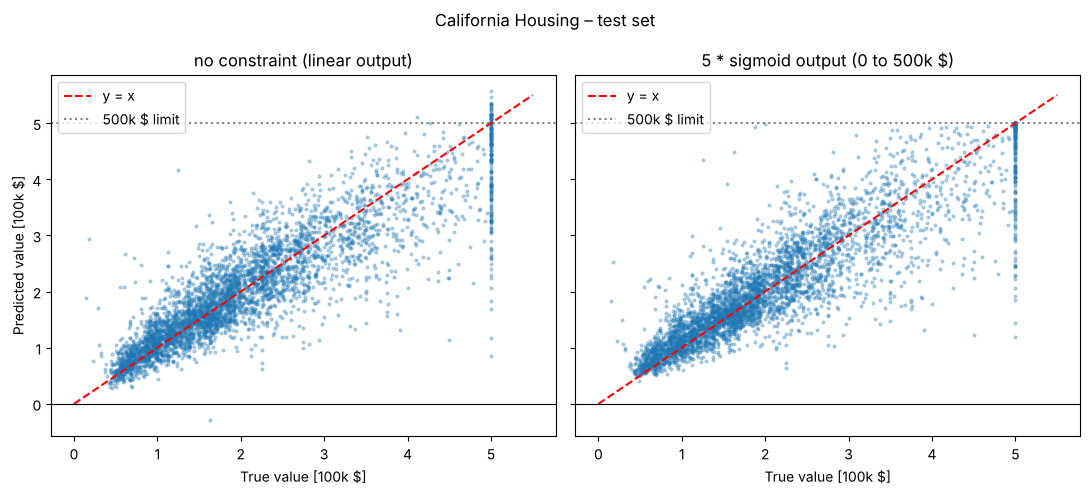

In [16]:
# Predicted vs. true values: unconstrained vs. bounded model
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, name in zip(axes, ["no constraint (linear output)", "5 * sigmoid output (0 to 500k $)"]):
    ax.scatter(yh_test, preds[name], s=4, alpha=0.3)
    ax.plot([0, 5.5], [0, 5.5], "r--", label="y = x")
    ax.axhline(5.0, color="gray", linestyle=":", label="500k $ limit")
    ax.axhline(0.0, color="black", linewidth=0.8)
    ax.set_title(name)
    ax.set_xlabel("True value [100k $]")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Predicted value [100k $]")
plt.suptitle("California Housing – test set")
plt.tight_layout()
plt.show()

**Result extra exercise**

With 5 · sigmoid all test predictions lie between 0.41 and 5.00, and the test MSE is 0.291, the same as without constraint. The unconstrained and the Softplus model predict more than 500k $ for 37 and 39 test districts, which cannot happen in this data. The bounded model predicts none above the limit.

The scatter plot shows the effect: the true values form a vertical line at 5.0 (the capped districts), and only the bounded model keeps all predictions below the 500k $ line. A drawback is that the sigmoid becomes flat near its limits, so gradients get small for districts close to 0 or 5. Note that the cap is a property of how the data was collected, not of real house prices, so the bound is correct for this dataset only.

**References**

Data

[1] Cassotti, M., Ballabio, D., Todeschini, R., & Consonni, V. (2015). A similarity-based QSAR model for predicting acute toxicity towards the fathead minnow (Pimephales promelas). SAR and QSAR in Environmental Research, 26(3), 217–243. Dataset: QSAR Fish Toxicity, UCI Machine Learning Repository, https://archive.ics.uci.edu/dataset/504/qsar+fish+toxicity (license CC BY 4.0), loaded from OpenML (dataset 44970, version 7), https://www.openml.org/d/44970.

[2] Pace, R. K., & Barry, R. (1997). Sparse spatial autoregressions. Statistics & Probability Letters, 33(3), 291–297. Dataset: California Housing, loaded with sklearn.datasets.fetch_california_housing.

Methods

[3] Prechelt, L. (1998). Early stopping – but when? In G. B. Orr & K.-R. Müller (Eds.), Neural Networks: Tricks of the Trade (pp. 55–69). Springer.

[4] Goodfellow, I., Bengio, Y., & Courville, A. (2016). Deep Learning. MIT Press, https://www.deeplearningbook.org (Chapter 6: output units such as Softplus; Section 7.8: early stopping).

Software

[5] Paszke, A. et al. (2019). PyTorch: An imperative style, high-performance deep learning library. Advances in Neural Information Processing Systems 32.

[6] Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. Journal of Machine Learning Research, 12, 2825–2830.

[7] Virtanen, P. et al. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. Nature Methods, 17, 261–272.

[8] Harris, C. R. et al. (2020). Array programming with NumPy. Nature, 585, 357–362.

[9] McKinney, W. (2010). Data structures for statistical computing in Python. Proceedings of the 9th Python in Science Conference, 56–61.

[10] Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. Computing in Science & Engineering, 9(3), 90–95.

Course material

[11] Introduction to Focus Areas, Data Science part, WS 2026/27: lecture slides on deep learning and the in-class PyTorch exercise (California Housing), whose preprocessing and training loop structure are reused here.